In [1]:
print("hero")

hero


Building a basic chatbot to simply get more handson on LangGraph because for agentic ai it is one of the most used package in the market

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages



In [2]:
class State(TypedDict):
    """Messages have the type "list". the `add_messages` function
    in the annotation defines how this state key should be updated 
    in this case it appends messages to the list rather than overwriting them"""
    messages:Annotated[list,add_messages]

graph_builder= StateGraph(State)

In [3]:
graph_builder

In [4]:

import os 
from dotenv import load_dotenv
load_dotenv()
print(os.getenv("GROQ_API_KEY"))

In [4]:
from  langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.4', 'langchain': '1.4.2'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001C7F51D1E80>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C7F51D2BA0>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
def chatbot(state:State):
    return {
        "messages":[llm.invoke(state["messages"])]
    }

In [8]:
graph_builder=StateGraph(State)
# adding node
graph_builder.add_node("llmchatbot",chatbot)
#adding_edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)
##at the end to create the graph we need to compile the same 

graph=graph_builder.compile()



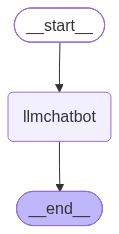

In [9]:
##To visualize the graph 
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [10]:
response=graph.invoke({"messages":"hi"})

In [11]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [12]:
for event in graph.stream({"messages":"hi how are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm just a bunch of code, but I'm functioning smoothly. How can I help you today?


Chatbot with Tool

In [13]:
from langchain_tavily import TavilySearch
tavily_tool=TavilySearch(
    max_results=5
)
tavily_tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph?',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norwegian Cr

In [14]:
def add(a:int,b:int)->int:
    """Add two number
    Args:
    a (int): first int
    b(int): second int 
    
    returns:
    int:output int
    """
    return a+b
def Multiply(a:int,b:int)->int:
    """
    Multiply two number
    Args:
    a(int): first Int
    b(int): second int
    
    returns:
    int: _description_output int"""
    return a*b


In [15]:
tools=[tavily_tool,Multiply,add]

In [16]:
llm_with_tools=llm.bind_tools(tools)

In [17]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.4', 'langchain': '1.4.2'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001A5BEECD7F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001A5BEECE510>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehens

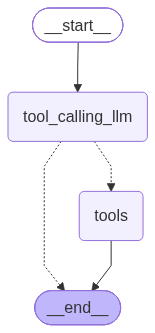

In [21]:
##reimporting all the libraries so that we get some ideas about the same 

from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

builder=StateGraph(State)
def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tools.invoke(state["messages"])]
    }
##adding node for the same
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
##here we are going to add edges simply which will going to define 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
#if the latest message (result) from assistant is a tool call then simply tools_condition routes to tools
# if the latest message (result) from assistant is not a tool call then simply tools_condition routes to End

tools_condition)
builder.add_edge("tools",END)
graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
response=graph.invoke({"messages":"what is 5 multiply 2 and then add 5?"})

In [33]:
print(response)

{'messages': [HumanMessage(content='what is 5 multiply 2 and then add 5?', additional_kwargs={}, response_metadata={}, id='af0ffd1d-e67d-4584-84f0-ab0b238fb0b3'), AIMessage(content='', additional_kwargs={'reasoning_content': "We need to compute 5 * 2 = 10, then add 5 = 15. We can use the Multiply function and add function. Let's do that.", 'tool_calls': [{'id': 'fc_3089ec78-2e12-4c3c-8de3-4353e4934846', 'function': {'arguments': '{"a":5,"b":2}', 'name': 'Multiply'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 418, 'total_tokens': 481, 'completion_time': 0.069793417, 'completion_tokens_details': {'reasoning_tokens': 36}, 'prompt_time': 0.024093719, 'prompt_tokens_details': None, 'queue_time': 0.320656018, 'total_time': 0.093887136}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_565badff47', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0d2db-1

In [31]:
for event in graph.stream({"messages":"what is 5 multiply 2 and then add 5"}):
    for value in event.values():
        print(value["messages"][-1].content)


10


###ReactAgent Architecture

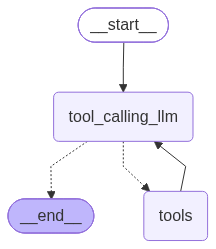

In [34]:
##reimporting all the libraries so that we get some ideas about the same 

from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

builder=StateGraph(State)
def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tools.invoke(state["messages"])]
    }
##adding node for the same
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
##here we are going to add edges simply which will going to define 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
#if the latest message (result) from assistant is a tool call then simply tools_condition routes to tools
# if the latest message (result) from assistant is not a tool call then simply tools_condition routes to End

tools_condition)
builder.add_edge("tools","tool_calling_llm")
graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
for event in graph.stream({"messages":"which job position in it field will be more trend and then multiply 40*50"}):
    for value in event.values():
        print(value["messages"][-1].content)


2000
**Trending IT Job Position (2026)**  
The IT landscape is rapidly evolving, but one role that consistently shows strong demand, high growth potential, and a clear future trajectory is **“Artificial Intelligence / Machine Learning Engineer”** (often shortened to AI/ML Engineer).  

| Why AI/ML Engineers are Trending | Key Points |
|----------------------------------|------------|
| **Ubiquitous AI Adoption** | From autonomous vehicles to personalized healthcare, AI is being integrated into almost every industry. |
| **Talent Shortage** | Companies struggle to find professionals who can design, train, and deploy production‑ready models. |
| **High Compensation & Mobility** | AI/ML roles command premium salaries and offer opportunities across tech giants, startups, finance, healthcare, and government. |
| **Cross‑Disciplinary Impact** | Skills in data engineering, software development, and domain knowledge are highly transferable. |
| **Continuous Learning** | Rapid advances (e.g., 

### Adding Memory In Agentic Graph

it requires because it solve persistent checkpoint problem
what basically we means is suppose if we ask llm chat bot hell my name is so and so and then it will reply politely back again if we ask question about is what is my name then it will not able to simply answer because there will be problem related to memory what happen llm is generative model it does not remember anything for that we have to save it somewhere at that time we need memory in agentic graph 

In [38]:
response=graph.invoke({"messages":"hello my name is ambuj singh?"})
print(response)

{'messages': [HumanMessage(content='hello my name is ambuj singh?', additional_kwargs={}, response_metadata={}, id='21a0660d-746f-4540-8163-a3a90c682da8'), AIMessage(content='Hello Ambuj! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hello my name is ambuj singh?" They might want a greeting. Probably respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 414, 'total_tokens': 462, 'completion_time': 0.051884676, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.022500002, 'prompt_tokens_details': None, 'queue_time': 0.306157727, 'total_time': 0.074384678}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_37c9245f64', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0d303-1337-74d1-a30d-e4d006ea0b72-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 414, 'output_tokens': 48

In [40]:
response=graph.invoke({"messages":"what is my name?"})
print(response)

{'messages': [HumanMessage(content='what is my name?', additional_kwargs={}, response_metadata={}, id='cea91c91-5def-4388-a4aa-595d7b7b2636'), AIMessage(content='I don’t have that information. If you tell me your name, I’ll remember it for the rest of our conversation.', additional_kwargs={'reasoning_content': 'User asks "what is my name?" We don\'t know. We should respond that we don\'t know.'}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 410, 'total_tokens': 465, 'completion_time': 0.0572525, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.085381989, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.394719318, 'total_time': 0.142634489}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0d303-84ca-7fd2-a39b-7077615c18ad-0', tool_calls=[], invalid_tool_calls=[], usage_metadata=

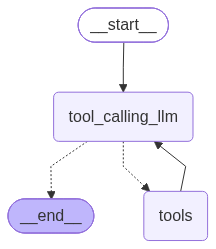

In [51]:
##reimporting all the libraries so that we get some ideas about the same 

from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()
builder=StateGraph(State)
def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tools.invoke(state["messages"])]
    }
##adding node for the same
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
##here we are going to add edges simply which will going to define 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
#if the latest message (result) from assistant is a tool call then simply tools_condition routes to tools
# if the latest message (result) from assistant is not a tool call then simply tools_condition routes to End

tools_condition)
builder.add_edge("tools","tool_calling_llm")
graph=builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [52]:
config={
    "configurable":{"thread_id":"1"}
}

In [53]:
res=graph.invoke({"messages":"hello my name is ambuj"},config=config)
print(res["messages"][-1].content)

Hello Ambuj! How can I help you today?


In [55]:
res=graph.invoke({"messages":"can you tell me my name?"},config=config)
print(res["messages"][-1].content)

Your name is Ambuj.


In [59]:
config={"configurable": {"thread_id":"3"}}

for chunk in graph.stream({"messages":"hi,my name is ambuj and i like to explore"},config=config,streaming_mode="updates"):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content='Hello Ambuj! 👋 It’s great to meet you. What kind of exploration are you thinking about? Tech, travel, science, or something else entirely? Let me know, and we can dive right in!', additional_kwargs={'reasoning_content': 'User says: "hi,my name is ambuj and i like to explore". They haven\'t asked a question. We can respond with a friendly greeting and ask what they\'d like to explore.'}, response_metadata={'token_usage': {'completion_tokens': 91, 'prompt_tokens': 416, 'total_tokens': 507, 'completion_time': 0.096222765, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.024781323, 'prompt_tokens_details': None, 'queue_time': 0.333867849, 'total_time': 0.121004088}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_639a5351c8', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0e6ab-cd51-7da1-8f1e-1efb2389992e-0', tool_calls=[], invalid_to

In [61]:
config={"configurable": {"thread_id":"3"}}

for chunk in graph.stream({"messages":"hi,my name is ambuj and i like to explore"},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='hi,my name is ambuj and i like to explore', additional_kwargs={}, response_metadata={}, id='d51889c3-52d6-4bca-903b-9c59c9fe347a'), AIMessage(content='Hello Ambuj! 👋 It’s great to meet you. What kind of exploration are you thinking about? Tech, travel, science, or something else entirely? Let me know, and we can dive right in!', additional_kwargs={'reasoning_content': 'User says: "hi,my name is ambuj and i like to explore". They haven\'t asked a question. We can respond with a friendly greeting and ask what they\'d like to explore.'}, response_metadata={'token_usage': {'completion_tokens': 91, 'prompt_tokens': 416, 'total_tokens': 507, 'completion_time': 0.096222765, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.024781323, 'prompt_tokens_details': None, 'queue_time': 0.333867849, 'total_time': 0.121004088}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_639a5351c8', 'service_tier': 'on_demand', 'finish_reason'

In [62]:
config={"configurable": {"thread_id":"4"}}

for chunk in graph.stream({"messages":"hi,my name is ambuj and i like to explore"},config=config,stream_mode="updates"):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content='Hi Ambuj! 👋 It’s great to meet you. What kind of exploration are you thinking about? Tech, travel, science, or something else? Let me know and we can dive in together!', additional_kwargs={'reasoning_content': 'User says: "hi,my name is ambuj and i like to explore". They haven\'t asked a question. We can respond with a friendly greeting and ask what they\'d like to explore. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 416, 'total_tokens': 509, 'completion_time': 0.102205238, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.025864283, 'prompt_tokens_details': None, 'queue_time': 0.308536763, 'total_time': 0.128069521}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_37c9245f64', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0e6b6-fb23-76e3-bf38-29c0dc6a1a6a-0', tool_calls=[], inva

In [64]:
config={"configurable": {"thread_id":"4"}}

for chunk in graph.stream({"messages":"i also like cricket and football"},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='hi,my name is ambuj and i like to explore', additional_kwargs={}, response_metadata={}, id='fc6bf1c5-c0aa-46ab-b262-fd39c3b7d342'), AIMessage(content='Hi Ambuj! 👋 It’s great to meet you. What kind of exploration are you thinking about? Tech, travel, science, or something else? Let me know and we can dive in together!', additional_kwargs={'reasoning_content': 'User says: "hi,my name is ambuj and i like to explore". They haven\'t asked a question. We can respond with a friendly greeting and ask what they\'d like to explore. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 416, 'total_tokens': 509, 'completion_time': 0.102205238, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.025864283, 'prompt_tokens_details': None, 'queue_time': 0.308536763, 'total_time': 0.128069521}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_37c9245f64', 'service_tier': 'on_demand', 'finish_r

In [65]:
config={"configurable": {"thread_id":"5"}}

async for chunk in graph.astream_events({"messages":"i also like cricket and football"},config=config,versions="v2"):
    print(chunk)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'i also like cricket and football'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a0e6bb-a370-78f3-85c5-a9b56e2ffad5', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='i also like cricket and football', additional_kwargs={}, response_metadata={}, id='c5bd2291-ed48-4046-aa49-dcc2c757d5bf')]}}, 'name': 'tool_calling_llm', 'tags': ['graph:step:1'], 'run_id': '01a0e6bb-a373-7163-871f-4e93aa91450f', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'tool_calling_llm', 'langgraph_triggers': ('branch:to:tool_calling_llm',), 'langgraph_path': ('__pregel_pull', 'tool_calling_llm'), 'langgraph_checkpoint_ns': 'tool_calling_llm:78a690c4-75e3-99f9-ba0a-53c22899a71a'}, 'parent_ids': ['01a0e6bb-a370-78f3-85c5-a9b56e2ffad5']}
{'event': 'on_chat_model_start', 'data': {'input': {'

In [16]:
from langchain_tavily import TavilySearch
from typing import Annotated
from langchain_core.tools import tool
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START,END
from langgraph.prebuilt import ToolNode,tools_condition

from langgraph.types import Command, interrupt

class State(TypedDict):
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

@tool
def human_assistance(query: str)->str:
    """Request assistance from a human"""
    human_response=interrupt({"query":query})
    return human_response["data"]

tool=TavilySearch(max_results=2)
tools=[tool,human_assistance]

llm_with_tools=llm.bind_tools(tools)

def chatbot(state:State):
    message=llm_with_tools.invoke(state["messages"])
    #because we will be interuptting during tool execution,
    #we disable parallel tool calling to avoid repeating any
    #tool invocation when we resume
    return {"messages":[message]}
memory=MemorySaver()
graph_builder.add_node("chatbot",chatbot)
tool_node=ToolNode(tools=tools)
graph_builder.add_node("tools",tool_node)
graph_builder.add_conditional_edges("chatbot",
tools_condition,)

graph_builder.add_edge("tools","chatbot")
graph_builder.add_edge(START,"chatbot")
graph=graph_builder.compile(checkpointer=memory)


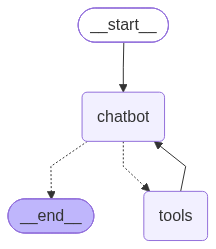

In [17]:
##To visualize the graph 
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [18]:
user_input="i need some expert guidance for building an agent. could you request assistance for me?"
config={"configurable":{"thread_id":"1"}}
events=graph.stream(
    {"messages":user_input},
    config=config,
    stream_mode="values"
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

i need some expert guidance for building an agent. could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_a26d7a69-c17e-4568-beb9-6bca767faa92)
 Call ID: fc_a26d7a69-c17e-4568-beb9-6bca767faa92
  Args:
    query: i need some expert guidance for building an agent
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_a26d7a69-c17e-4568-beb9-6bca767faa92)
 Call ID: fc_a26d7a69-c17e-4568-beb9-6bca767faa92
  Args:
    query: i need some expert guidance for building an agent


In [19]:
## so for simply human response we need to simply provide response from the user then only it will going to strat the execution

human_reponse=(
    "we,the experts are here to help, wewould recommend you check out langgraph to build your agent."
    "it is much more reliable and extensible than simple autonomous agents"
)

human_command=Command(resume={"data":human_reponse})
events=graph.stream(human_command,config,stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_a26d7a69-c17e-4568-beb9-6bca767faa92)
 Call ID: fc_a26d7a69-c17e-4568-beb9-6bca767faa92
  Args:
    query: i need some expert guidance for building an agent
================================= Tool Message =================================
Name: human_assistance

we,the experts are here to help, wewould recommend you check out langgraph to build your agent.it is much more reliable and extensible than simple autonomous agents
================================== Ai Message ==================================

Absolutely—let’s walk through a practical, step‑by‑step roadmap for building a robust, production‑ready agent. I’ll cover the core concepts, the most popular toolchains (LangChain, LangGraph, LlamaIndex, etc.), and give you concrete code snippets you can copy‑paste and tweak. Feel free to ask follow‑up questions on any part that needs more detail!

---

## 1. Clarify the A